# 1. Data collection and cleaning

This notebook loads the three data sources, checks their quality and explains the cleaning
decisions that the rest of the project depends on.

| Source | What | How it gets here |
|---|---|---|
| Dublin Bikes history (data.smartdublin.ie, CC BY 4.0) | one CSV per month, a reading per station every 5 to 10 min | `python -m bikes.history` downloads each month and keeps only the columns that change, as parquet |
| Met Éireann hourly, Dublin Airport (data.gov.ie, CC BY 4.0) | rain, temperature, wind, humidity per hour | `bikes.weather.download_hourly()` |
| Dublin Bikes live feed (GBFS v2.3) | current reading for all 115 stations | `python -m bikes.collector`, every 5 min from GitHub Actions into Supabase |

The code lives in the `bikes/` package rather than in notebook cells, so the collector, the
notebooks and the dashboard all share one tested implementation.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from bikes.features import build_grid, load_history, load_stations
from bikes.weather import load_hourly

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

## 1.1 Bike history
18 months, January 2025 to June 2026. Each monthly CSV is 100+ MB because the station name,
address and coordinates repeat on every row. Stored as parquet without those columns, all 18
months take about 30 MB.

In [2]:
raw = load_history()
stations = load_stations()
print(f"{len(raw):,} readings, {raw['station_id'].nunique()} stations, "
      f"{raw['last_reported'].min()} to {raw['last_reported'].max()} (UTC)")
raw.head()

10,788,707 readings, 115 stations, 2025-01-01 00:05:00 to 2026-06-30 23:55:00 (UTC)


,last_reported,station_id,num_bikes_available,num_docks_available,is_installed,is_renting,is_returning,capacity
0,2025-01-01 00:05:00,1,1,30,True,True,True,31
1,2025-01-01 00:05:00,10,9,7,True,True,True,16
2,2025-01-01 00:05:00,101,7,23,True,True,True,30
3,2025-01-01 00:05:00,102,6,34,True,True,True,40
4,2025-01-01 00:05:00,103,4,36,True,True,True,40


DuckDB can query the parquet files directly with SQL, without loading them into pandas first.
Handy for quick checks across all months:

In [3]:
import duckdb
per_month = duckdb.sql("""
    select strftime(last_reported, '%Y-%m')                     as month,
           count(*)                                            as readings,
           count(distinct station_id)                          as stations,
           round(count(*) / count(distinct station_id)
                 / count(distinct cast(last_reported as date)), 1) as readings_per_station_per_day
    from '../data/history/20*.parquet'
    group by 1 order by 1
""").df()
per_month

,month,readings,stations,readings_per_station_per_day
0,2025-01,608128,114,172.1
1,2025-02,547552,114,171.5
2,2025-03,629103,114,178.0
3,2025-04,610962,114,178.6
4,2025-05,640308,115,179.6
5,2025-06,606948,115,175.9
6,2025-07,601170,115,174.3
7,2025-08,639029,115,179.3
8,2025-09,622950,115,180.6
9,2025-10,642050,115,180.1


January and February 2026 have fewer readings in total. Per station per day the rate is only
a little lower, so the next cell checks whether whole days are missing.

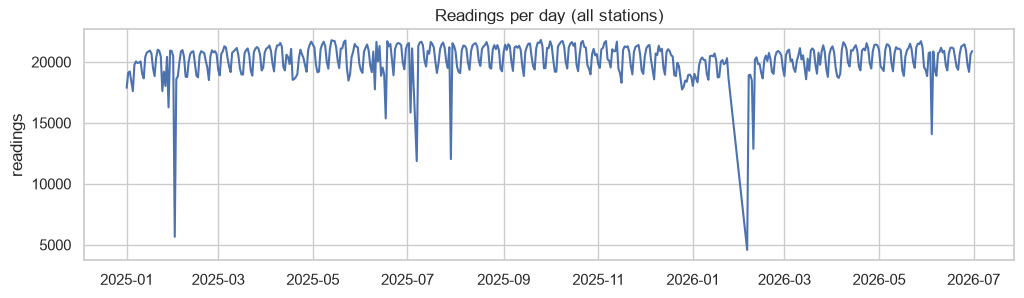

2 days with less than half the usual number of readings


last_reported
2025-02-01    5661
2026-02-05    4580
dtype: int64

In [4]:
daily = raw.groupby(raw["last_reported"].dt.date).size()
fig, ax = plt.subplots(figsize=(12, 3))
daily.plot(ax=ax)
ax.set(title="Readings per day (all stations)", xlabel="", ylabel="readings")
plt.show()
low_days = daily[daily < daily.median() * 0.5]
print(f"{len(low_days)} days with less than half the usual number of readings")
low_days.head(15)

### How often does a station report?

count    10788592.0
mean            8.4
std            57.2
min             5.0
50%            10.0
90%            10.0
99%            10.0
max         43390.0
Name: last_reported, dtype: float64


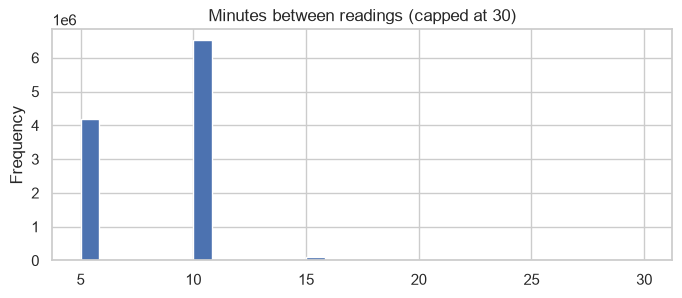

In [5]:
gaps = (raw.sort_values("last_reported")
           .groupby("station_id")["last_reported"].diff().dt.total_seconds() / 60)
print(gaps.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
gaps.clip(upper=30).plot.hist(bins=30, figsize=(8, 3), title="Minutes between readings (capped at 30)")
plt.show()

Only two days have less than half the usual readings, so January and February 2026 are short
because of a lower rate on many days rather than big holes. A few very long gaps (the max)
are stations that were out of service for days or weeks.

Readings come every 5 or 10 minutes. To compare stations at the same moment I resample onto a
fixed **10-minute grid** (`bikes.features.build_grid`):

* the latest reading in each slot wins;
* a missing slot is filled from the previous reading for at most 20 minutes, longer gaps stay
  empty so they can never become fake training targets;
* readings where the station is **not installed or not renting** are dropped. A closed station
  reports 0 bikes, which would teach the model that "closed" means "empty".

In [6]:
closed = ~(raw["is_installed"] & raw["is_renting"])
print(f"{closed.mean():.2%} of readings come from a closed / not-renting station")
raw[closed].groupby("station_id").size().sort_values(ascending=False).head(8)

0.16% of readings come from a closed / not-renting station


station_id
51    9742
93      95
94      73
83      72
86      72
5       71
50      70
7       70
dtype: int64

Only 0.16% of readings are from closed stations, and most of those are one station (51),
which was out of service for a long stretch. The scheme also closes overnight (about 00:30 to
05:00), when every station reports "not renting"; the live collector checks for that.

In [7]:
grid = build_grid(raw)
print(f"grid: {len(grid):,} rows ({len(grid) / len(raw):.0%} of the raw readings)")
grid.head()

grid: 8,733,281 rows (81% of the raw readings)


,time,station_id,bikes,docks,capacity
0,2025-01-01 00:00:00+00:00,1,1,30,31
1,2025-01-01 00:10:00+00:00,1,1,30,31
2,2025-01-01 00:20:00+00:00,1,1,30,31
3,2025-01-01 00:30:00+00:00,1,1,30,31
4,2025-01-01 00:40:00+00:00,1,1,30,31


### Rebalancing
Dublin City Council's vans move bikes between stations. That shows up as a jump of many bikes
inside one 10-minute slot, much bigger than riders could cause. These jumps are real (they
are what a user sees) so they stay in the data, but they are the main thing no model can
predict from the past alone.

In [8]:
grid = grid.sort_values(["station_id", "time"])
step = grid.groupby("station_id")["bikes"].diff()
print("Change in bikes per 10 minutes:")
print(step.abs().describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(2))
big = step.abs() >= 8
print(f"\n{big.sum():,} jumps of 8+ bikes in 10 minutes ({big.mean():.3%} of slots), "
      f"about {big.sum() / grid['time'].dt.date.nunique():.0f} a day")

Change in bikes per 10 minutes:


count    8733166.00
mean           0.46
std            1.11
min            0.00
50%            0.00
90%            1.00
99%            4.00
99.9%         14.00
max           39.00
Name: bikes, dtype: float64



33,690 jumps of 8+ bikes in 10 minutes (0.386% of slots), about 63 a day


### Capacity
The `capacity` column is the number of docks. Bikes + free docks is usually a bit lower,
because broken docks count as neither.

In [9]:
usable = grid["bikes"] + grid["docks"]
print(f"bikes + docks equals capacity in {(usable == grid['capacity']).mean():.1%} of slots, "
      f"below it in {(usable < grid['capacity']).mean():.1%}")
stations.sort_values("capacity").describe()["capacity"]

bikes + docks equals capacity in 95.3% of slots, below it in 4.7%


count    115.000000
mean      31.973913
std        7.563139
min       16.000000
25%       29.000000
50%       30.000000
75%       40.000000
max       40.000000
Name: capacity, dtype: float64

## 1.2 Weather
Hourly observations from Dublin Airport, about 9 km north of the city centre. Wind is
converted from knots to m/s so it matches the units of the live forecast.

In [10]:
weather = load_hourly()
weather = weather[(weather["time"] >= "2025-01-01") & (weather["time"] < "2026-07-01")]
print(f"{len(weather):,} hours, missing values per column:")
print(weather.isna().sum())
weather.describe().round(2)

13,104 hours, missing values per column:
time        0
rain_mm     0
temp_c      0
wind_ms     0
humidity    0
dtype: int64


,rain_mm,temp_c,wind_ms,humidity
count,13104.00,13104.00,13104.00,13104.00
mean,0.10,10.28,4.64,80.79
std,0.43,5.12,2.24,12.30
min,0.00,-5.30,0.00,30.00
25%,0.00,6.60,3.09,73.00
50%,0.00,10.20,4.12,83.00
75%,0.00,13.90,6.17,90.00
max,9.40,27.60,15.95,100.00


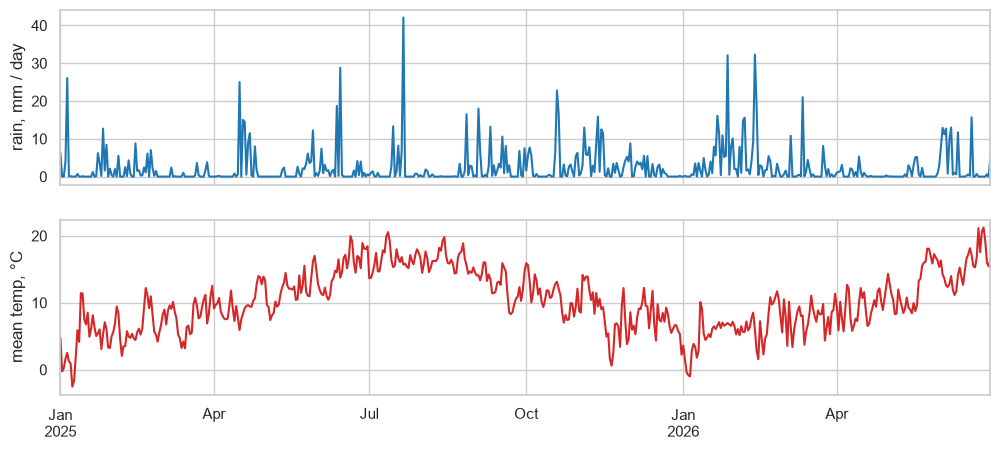

It rained (>= 0.2 mm) in 10% of hours


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
weather.set_index("time")["rain_mm"].resample("D").sum().plot(ax=axes[0], color="tab:blue")
axes[0].set(ylabel="rain, mm / day")
weather.set_index("time")["temp_c"].resample("D").mean().plot(ax=axes[1], color="tab:red")
axes[1].set(ylabel="mean temp, °C", xlabel="")
plt.show()
print(f"It rained (>= 0.2 mm) in {(weather['rain_mm'] >= 0.2).mean():.0%} of hours")

## 1.3 Time zone check
The history timestamps have no zone attached. If they were Irish local time, the morning rush
would sit at the same clock hour all year. In UTC it should move one hour earlier during
summer time (IST = UTC+1). The busiest morning hour, measured as the hour when the fewest
bikes are sitting in docks across the network, does move:

In [12]:
weekday = grid[grid["time"].dt.day_of_week < 5]
docked = weekday.groupby("time")["bikes"].sum()
by_month_hour = docked.groupby([docked.index.month, docked.index.hour]).mean().unstack()
morning = by_month_hour.loc[:, 5:11]
print("Busiest morning hour (UTC) by month:", morning.idxmin(axis=1).to_dict())

Busiest morning hour (UTC) by month: {1: 8, 2: 8, 3: 8, 4: 7, 5: 7, 6: 7, 7: 7, 8: 7, 9: 7, 10: 7, 11: 8, 12: 8}


Busiest morning hour is 08:00 UTC in winter months and 07:00 UTC in summer months, which is
08:00 Irish time all year. So the timestamps are **UTC**. Everything is stored in UTC and only
converted to Irish time for hour-of-day features.

## 1.4 Live collection
`bikes/collector.py` runs every 5 minutes on GitHub Actions. Each run:
1. reads the GBFS `station_status` and `station_information` feeds,
2. writes readings to the `snapshots` table in Supabase (`sql/schema.sql`); duplicates are
   dropped by the primary key `(station_id, last_reported)`,
3. predicts 10, 30 and 60 minutes ahead and writes those to `predictions`, so the
   `prediction_accuracy` view can later compare each prediction with what really happened.

Without a `DATABASE_URL` it falls back to local parquet files, which is what runs here:

In [13]:
from bikes.live import fetch_status
live = fetch_status()
print(f"{len(live)} stations right now, {(live['bikes'] == 0).sum()} empty, {(live['docks'] == 0).sum()} full")
live.head()

115 stations right now, 22 empty, 6 full


,station_id,last_reported,bikes,docks,is_installed,is_renting,is_returning,capacity
0,1,2026-11-02 23:55:26+00:00,0,31,True,False,True,31
1,2,2026-11-02 23:53:43+00:00,17,3,True,False,True,20
2,3,2026-11-02 23:52:06+00:00,13,7,True,False,True,20
3,4,2026-11-03 00:01:35+00:00,3,16,True,False,True,19
4,5,2026-11-02 23:52:43+00:00,39,1,True,False,True,40
